# Clase 5 · Feature engineering, pipelines y desbalanceo

La semana pasada preparamos los datos **a mano**, paso a paso. Hoy damos tres pasos más:

1. **Feature engineering:** crear variables nuevas que ayuden al modelo.
2. **Pipelines:** meter todos los pasos en un único objeto, sin fugas y sin repetir código.
3. **Desbalanceo:** qué hacer cuando casi todos los casos son de una clase.

Seguimos con el Titanic. Ejecuta las celdas **en orden** y, antes de cada una, piensa qué esperas que salga.

## 0. Preparación

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

AZUL, OSCURO = "#4D97FF", "#111D33"
sns.set_theme(style="whitegrid", palette=[AZUL, OSCURO])

df = pd.read_csv("titanic.csv")
print("Cargado:", df.shape[0], "filas y", df.shape[1], "columnas")

Cargado: 891 filas y 12 columnas


## 1. Feature engineering

Un modelo solo ve **las columnas que le damos**. Si una información útil está escondida (en un texto, en una suma, en una fecha), el modelo no la usa. El *feature engineering* consiste en **sacarla a la luz** creando columnas nuevas.

Hay una regla importante: estas columnas se calculan **solo con la propia fila** (sumas, trozos de texto, fechas), así que se pueden crear **antes de partir** sin hacer trampa.

### 1.1 Combinar columnas: tamaño de la familia

`SibSp` (hermanos o cónyuge) y `Parch` (padres o hijos) por separado dicen poco. Juntas dicen cuánta gente viajaba contigo.

In [19]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1        # +1 para contarte a ti mismo
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print(df.groupby("IsAlone")["Survived"].mean().round(2))
df.groupby("FamilySize")["Survived"].agg(["mean", "count"]).round(2)

IsAlone
0    0.51
1    0.30
Name: Survived, dtype: float64


,mean,count
FamilySize,,
1,0.30,537
2,0.55,161
3,0.58,102
4,0.72,29
5,0.20,15
6,0.14,22
7,0.33,12
8,0.00,6
11,0.00,7


Quien viaja **solo** sobrevive el 30 %; quien viaja acompañado, el 51 %. Las familias de 4 personas son las que mejor salen (72 %), pero con pocos casos: hay que fijarse en el recuento (`count`) antes de fiarse de un porcentaje.

### 1.2 Extraer de un texto: el título del nombre

En `Name` hay información escondida: `"Braund, Mr. Owen Harris"`. El **título** (Mr, Mrs, Miss, Master…) resume sexo, edad aproximada y estado civil.

In [20]:
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
print(df["Title"].value_counts().head(8))

Title
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Rev         6
Major       2
Mlle        2
Name: count, dtype: int64


Hay títulos muy poco frecuentes (Dr, Rev, Col…). Los unimos todos en «Rare» para no crear columnas con dos o tres casos:

In [21]:
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
df.groupby("Title")["Survived"].agg(["mean", "count"]).round(2)

,mean,count
Title,,
Master,0.57,40
Miss,0.70,185
Mr,0.16,517
Mrs,0.79,126
Rare,0.35,23


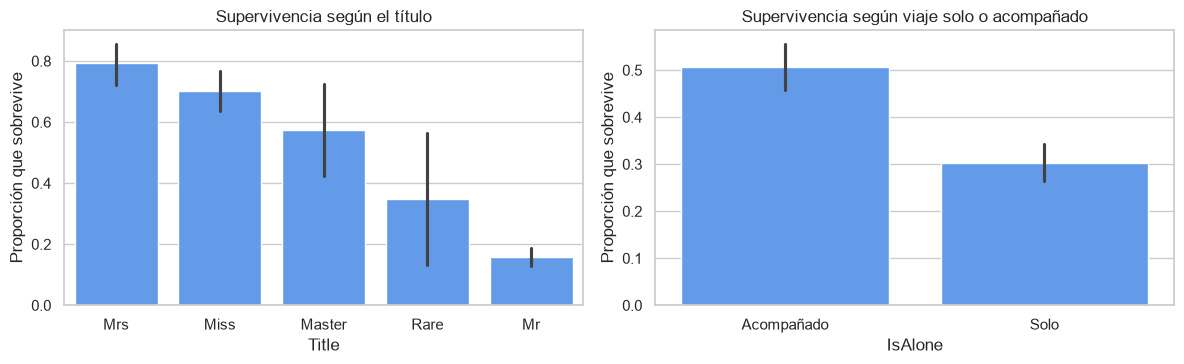

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(data=df, x="Title", y="Survived", order=["Mrs", "Miss", "Master", "Rare", "Mr"], color=AZUL, ax=axs[0])
axs[0].set_title("Supervivencia según el título")
axs[0].set_ylabel("Proporción que sobrevive")
sns.barplot(data=df, x="IsAlone", y="Survived", color=AZUL, ax=axs[1])
axs[1].set_xticks([0, 1], ["Acompañado", "Solo"])
axs[1].set_title("Supervivencia según viaje solo o acompañado")
axs[1].set_ylabel("Proporción que sobrevive")
plt.tight_layout()
plt.show()

El título separa muy bien: **Mrs 79 %, Miss 70 %, Master (niños) 57,5 %, Mr 16 %**. Una sola columna nueva con mucha información.

### 1.3 Transformar y resumir

Dos ideas más, que ya conocéis:

- `HasCabin`: ya vimos que faltar `Cabin` también es información.
- Un **logaritmo** para variables muy sesgadas, como `Fare` (lo vimos en el EDA): `np.log1p(df["Fare"])`.

In [23]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["LogFare"] = np.log1p(df["Fare"])
df[["Fare", "LogFare"]].describe().round(2)

,Fare,LogFare
count,891.00,891.00
mean,32.20,2.96
std,49.69,0.97
min,0.00,0.00
25%,7.91,2.19
50%,14.45,2.74
75%,31.00,3.47
max,512.33,6.24


### 1.4 ¿Mejoran el modelo?

Crear columnas **no garantiza** mejorar. Hay que comprobarlo. Primero preparamos las columnas finales (descartamos las que no aportan, como la semana pasada):

In [24]:
y = df["Survived"]
X = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin", "LogFare"])
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title,HasCabin
0,3,male,22.0,1,0,7.2500,S,2,0,Mr,0
1,1,female,38.0,1,0,71.2833,C,2,0,Mrs,1
2,3,female,26.0,0,0,7.9250,S,1,1,Miss,0
3,1,female,35.0,1,0,53.1000,S,2,0,Mrs,1
4,3,male,35.0,0,0,8.0500,S,1,1,Mr,0


## 2. Pipelines

La semana pasada, para preparar los datos escribimos una función `preparar` con unas veinte líneas: imputar, codificar, escalar… y **no olvidarnos** de aplicar cada paso a la prueba. Es fácil equivocarse. Un **pipeline** lo hace por nosotros.

Dos piezas:

- **`ColumnTransformer`:** aplica un tratamiento distinto a cada grupo de columnas (las numéricas se imputan y se escalan; las categóricas se imputan y se codifican).
- **`Pipeline`:** encadena pasos (el preprocesado y el modelo) en un solo objeto.

### 2.1 El preprocesado

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin"]
categoricas = ["Sex", "Embarked", "Title"]

num = Pipeline([("imputar", SimpleImputer(strategy="median")),
                ("escalar", StandardScaler())])
cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocesado = ColumnTransformer([
    ("num", num, numericas),
    ("cat", cat, categoricas),
])
preprocesado

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### 2.2 El pipeline completo: preprocesado + modelo

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

modelo = Pipeline([
    ("preprocesado", preprocesado),
    ("modelo", LogisticRegression(max_iter=1000)),
])

modelo.fit(X_train, y_train)          # aprende TODO con el entrenamiento
print(f"Nota en prueba: {modelo.score(X_test, y_test):.1%}")

Nota en prueba: 83.8%


Con **dos líneas** (`fit` y `score`) se han hecho todos los pasos de la semana pasada, y en el orden correcto: lo que se aprende (medianas, categorías, medias) sale **solo del entrenamiento**. Podemos ver en qué columnas se ha convertido la tabla:

In [27]:
nombres = modelo.named_steps["preprocesado"].get_feature_names_out()
print(len(nombres), "columnas:")
print(list(nombres))

17 columnas:
['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'num__FamilySize', 'num__HasCabin', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Rare']


### 2.3 ¿Mejoraron las variables nuevas?

Comparamos el mismo modelo con y sin las columnas nuevas (`FamilySize`, `HasCabin`, `Title`). Para que la nota sea más fiable usamos **validación cruzada**: repite el reparto 5 veces y promedia (la veremos a fondo más adelante en el curso). Con un pipeline **no hay fuga** en ninguna de las repeticiones, porque el preprocesado se aprende de nuevo con el entrenamiento de cada una.

In [28]:
from sklearn.model_selection import cross_val_score

def construir(num_cols, cat_cols, clasificador):
    prep = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])
    return Pipeline([("preprocesado", prep), ("modelo", clasificador)])

base_num, base_cat = ["Pclass", "Age", "SibSp", "Parch", "Fare"], ["Sex", "Embarked"]
nuevo_num, nuevo_cat = base_num + ["FamilySize", "HasCabin"], base_cat + ["Title"]

print(f"{'':16}{'sin variables nuevas':>22}{'con variables nuevas':>22}")
modelos = {"Regresión logística": LogisticRegression(max_iter=1000)}
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
modelos["Árbol (prof. 3)"] = DecisionTreeClassifier(max_depth=3, random_state=42)
modelos["KNN"] = KNeighborsClassifier()
for nombre, clasificador in modelos.items():
    antes = cross_val_score(construir(base_num, base_cat, clasificador), X, y, cv=5).mean()
    despues = cross_val_score(construir(nuevo_num, nuevo_cat, clasificador), X, y, cv=5).mean()
    print(f"{nombre:16}{antes:>22.1%}{despues:>22.1%}")

                  sin variables nuevas  con variables nuevas
Regresión logística                 78.8%                 82.8%
Árbol (prof. 3)                  80.9%                 82.3%
KNN                              80.9%                 81.3%


La regresión logística mejora **cuatro puntos** (78,8 % a 82,8 %); el árbol y el KNN mejoran muy poco. Moraleja: un buen *feature* ayuda sobre todo a los modelos que no pueden descubrirlo solos, y **hay que medir**, no suponer.

Fíjate también en lo fácil que ha sido **cambiar de modelo**: solo cambia el último paso del pipeline.

### 2.4 Guardar el pipeline y usarlo con datos nuevos

Un pipeline es **un único objeto**: se guarda y se carga con todo lo que ha aprendido. En producción se aplica a una tabla en bruto, sin repetir el preprocesado.

In [29]:
import joblib

joblib.dump(modelo, "modelo_titanic.joblib")
cargado = joblib.load("modelo_titanic.joblib")

nuevo = pd.DataFrame([{"Pclass": 1, "Sex": "female", "Age": 30, "SibSp": 0, "Parch": 0, "Fare": 80.0,
                       "Embarked": "S", "FamilySize": 1, "IsAlone": 1, "Title": "Miss", "HasCabin": 1}])
print("Probabilidad de sobrevivir:", round(cargado.predict_proba(nuevo)[0, 1], 2))

Probabilidad de sobrevivir: 0.95


> El pasajero nuevo llega **en bruto** (con texto y sin escalar). El pipeline ya sabe qué hacer con cada columna.

## 3. Datos desbalanceados

En el Titanic, el 38 % sobrevive: está bastante equilibrado. En muchos problemas reales la clase interesante es **rara** (fraude, averías, abandono grave). Para verlo creamos una versión desbalanceada: **todos los fallecidos y solo 45 supervivientes** (un 7,6 %).

In [30]:
muertos = df[df["Survived"] == 0]
vivos = df[df["Survived"] == 1].sample(45, random_state=0)
raro = pd.concat([muertos, vivos]).sample(frac=1, random_state=0)

y_r = raro["Survived"]
X_r = raro.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin", "LogFare"])
print("Filas:", len(raro), "· Supervivientes:", round(y_r.mean() * 100, 1), "%")

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.3, stratify=y_r, random_state=42)
print("Supervivientes en la prueba:", yr_test.sum(), "de", len(yr_test))
print(f"Un modelo que SIEMPRE dice «murió» acierta: {1 - yr_test.mean():.1%}")

Filas: 594 · Supervivientes: 7.6 %
Supervivientes en la prueba: 14 de 179
Un modelo que SIEMPRE dice «murió» acierta: 92.2%


### 3.1 Cuando la nota engaña

Entrenamos el pipeline normal y medimos dos cosas:

- **Aciertos (accuracy):** de todos los pasajeros, ¿cuántos clasifica bien?
- **Recall:** de los supervivientes **reales**, ¿cuántos detecta? (más adelante en el curso veremos las métricas con calma).

In [31]:
from sklearn.metrics import recall_score, precision_score, confusion_matrix

normal = construir(nuevo_num, nuevo_cat, LogisticRegression(max_iter=1000)).fit(Xr_train, yr_train)
pred = normal.predict(Xr_test)
print(f"Aciertos: {normal.score(Xr_test, yr_test):.1%} · Recall: {recall_score(yr_test, pred):.1%}")
print("Matriz de confusión (filas = real, columnas = predicho):")
print(confusion_matrix(yr_test, pred))

Aciertos: 93.3% · Recall: 35.7%
Matriz de confusión (filas = real, columnas = predicho):
[[162   3]
 [  9   5]]


Saca **93,3 %** de aciertos (el modelo «siempre murió» saca 92,2 %): parece buenísimo. Pero **solo detecta 5 de los 14 supervivientes** (recall 35,7 %). La nota alta es un espejismo causado por el desbalanceo.

### 3.2 Remedio 1: `class_weight="balanced"`

Le decimos al modelo que **fallar en la clase pequeña cuesta más**.

In [32]:
equilibrado = construir(nuevo_num, nuevo_cat, LogisticRegression(max_iter=1000, class_weight="balanced")).fit(Xr_train, yr_train)
pred = equilibrado.predict(Xr_test)
print(f"Aciertos: {equilibrado.score(Xr_test, yr_test):.1%} · Recall: {recall_score(yr_test, pred):.1%} · Precisión: {precision_score(yr_test, pred):.1%}")
print(confusion_matrix(yr_test, pred))

Aciertos: 79.9% · Recall: 57.1% · Precisión: 21.1%
[[135  30]
 [  6   8]]


Los aciertos **bajan** (79,9 %), pero el recall **sube** (57,1 %): detecta más supervivientes, a costa de más falsas alarmas. No hay un resultado «mejor» en abstracto: depende de **qué error cuesta más** en cada problema (lo veremos con calma más adelante en el curso).

### 3.3 Remedio 2: sobremuestrear… solo el entrenamiento

Repetimos al azar casos de la clase pequeña hasta igualar las dos clases. **Regla de oro:** solo se remuestrea el **entrenamiento**. La prueba se queda tal como es; si no, estaríamos copiando casos de entrenamiento a la prueba (fuga, como los duplicados de la semana pasada).

In [33]:
from sklearn.utils import resample

entrenamiento = Xr_train.assign(Survived=yr_train)
pocos = entrenamiento[entrenamiento["Survived"] == 1]
muchos = entrenamiento[entrenamiento["Survived"] == 0]
pocos_repetidos = resample(pocos, replace=True, n_samples=len(muchos), random_state=42)
igualado = pd.concat([muchos, pocos_repetidos])
print("Entrenamiento igualado:", igualado["Survived"].value_counts().to_dict())

sobre = construir(nuevo_num, nuevo_cat, LogisticRegression(max_iter=1000))
sobre.fit(igualado.drop(columns="Survived"), igualado["Survived"])
pred = sobre.predict(Xr_test)                    # la prueba, SIN tocar
print(f"Aciertos: {sobre.score(Xr_test, yr_test):.1%} · Recall: {recall_score(yr_test, pred):.1%}")

Entrenamiento igualado: {0: 384, 1: 384}
Aciertos: 80.4% · Recall: 57.1%


Resultado parecido al de `class_weight`. Otras técnicas (como **SMOTE**, que *inventa* casos nuevos parecidos a los reales) están en la librería `imbalanced-learn`; el principio es el mismo y también **solo se aplican al entrenamiento**.

> Con solo 14 supervivientes en la prueba, los números exactos cambian de un reparto a otro. Lo que **no** cambia es el patrón: el modelo normal parece bueno y detecta poco; el equilibrado detecta más y acierta menos en total.

## 4. Resumen

| Tema | Idea |
|---|---|
| Feature engineering | Crear columnas con conocimiento del problema; comprobar siempre si mejoran |
| Reglas | Calcularlas con la propia fila (o dentro del pipeline si usan estadísticos); cuidado con usar la etiqueta |
| `ColumnTransformer` | Un tratamiento distinto para cada grupo de columnas |
| `Pipeline` | Preprocesado y modelo en un objeto: sin fuga, menos código, cambiar de modelo en una línea, se guarda y se reutiliza |
| Desbalanceo | La nota global engaña; mirar el recall; `class_weight` o remuestrear **solo el entrenamiento** |

---
**Siguiente paso:** práctica individual *Reto: reservas de un hotel* (`practica_reservas_hotel.ipynb`).